# Model Training 1: Linear Regression

In [32]:
# imports
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import seaborn as sns

In [33]:
# read data
train_df = pd.read_csv("../Data/TrainPreprocessed.csv")
test_df = pd.read_csv("../Data/TestPreprocessed.csv")

In [34]:
# separate features and label
X_train = train_df.drop(columns=["LIFETIME"])
y_train = train_df["LIFETIME"]

X_test = test_df.drop(columns=["LIFETIME"])
y_test = test_df["LIFETIME"]

In [35]:
# function to plot model evaluation
sns.set_theme(style="whitegrid")

def plot_model_evaluation(y_true, y_pred, title="Model Evaluation"):
    """
    Plot residual, prediction, and ground truth diagnostics for regression models.
    
    Parameters:
        y_true (array-like): Ground truth values
        y_pred (array-like): Model predictions
        title (str): Title of the overall plot
    """
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    residuals = y_pred - y_true

    # Create figure layout
    fig, axs = plt.subplots(3, 2, figsize=(14, 14))
    fig.suptitle(title, fontsize=16)

    # 1. Residual Histogram
    sns.histplot(residuals, bins=60, ax=axs[0, 0], color="C0")
    axs[0, 0].set_title("Residual Histogram")
    axs[0, 0].set_xlabel("Residual")
    axs[0, 0].set_ylabel("Density")

    # 2. Ground Truth Histogram
    sns.histplot(y_true, bins=60, ax=axs[0, 1], color="C0")
    axs[0, 1].set_title("Ground Truth Histogram")
    axs[0, 1].set_xlabel("Ground truth")
    axs[0, 1].set_ylabel("Density")

    # 3. Prediction Histogram
    sns.histplot(y_pred, bins=60, ax=axs[1, 0], color="C0")
    axs[1, 0].set_title("Prediction Histogram")
    axs[1, 0].set_xlabel("Prediction")
    axs[1, 0].set_ylabel("Density")

    # 4. Ground Truth vs Predictions (binned)
    df_gt_pred = pd.DataFrame({"ground_truth": y_true, "prediction": y_pred})
    df_gt_pred["gt_bin"] = pd.cut(df_gt_pred["ground_truth"], bins=30)
    binned_gt = df_gt_pred.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["prediction"], label="Prediction", color="darkorange")
    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["ground_truth"], linestyle="--", color="C0", label="Ideal")
    axs[1, 1].set_title("Ground Truth vs Predictions (Binned)")
    axs[1, 1].set_xlabel("Ground Truth")
    axs[1, 1].set_ylabel("Prediction")
    axs[1, 1].legend()

    # 5. Predictions vs Residual (binned)
    df_pred_res = pd.DataFrame({"prediction": y_pred, "residual": residuals})
    df_pred_res["pred_bin"] = pd.cut(df_pred_res["prediction"], bins=30)
    binned_pred = df_pred_res.groupby("pred_bin", observed=False).mean(numeric_only=True)

    axs[2, 0].plot(binned_pred["prediction"], binned_pred["residual"], color="darkorange")
    axs[2, 0].axhline(0, linestyle="--", color="C0")
    axs[2, 0].set_title("Predictions vs Residual (Binned)")
    axs[2, 0].set_xlabel("Prediction")
    axs[2, 0].set_ylabel("Residual")

    # 6. Ground Truth vs Residual (binned)
    df_gt_res = pd.DataFrame({"ground_truth": y_true, "residual": residuals})
    df_gt_res["gt_bin"] = pd.cut(df_gt_res["ground_truth"], bins=30)
    binned_gt_res = df_gt_res.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[2, 1].plot(binned_gt_res["ground_truth"], binned_gt_res["residual"], color="darkorange")
    axs[2, 1].axhline(0, linestyle="--", color="C0")
    axs[2, 1].set_title("Ground Truth vs Residual (Binned)")
    axs[2, 1].set_xlabel("Ground Truth")
    axs[2, 1].set_ylabel("Residual")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


### 1. Baseline Linear Regression

In [36]:
# train linear regressor
lr_model1 = LinearRegression()
lr_model1.fit(X_train, y_train)

LinearRegression()

In [37]:
# predict
y_pred_lr1 = lr_model1.predict(X_test)

In [38]:
# evaluate
mae_lr1 = mean_absolute_error(y_test, y_pred_lr1)
mse_lr1 = mean_squared_error(y_test, y_pred_lr1)
rmse_lr1 = np.sqrt(mse_lr1)
r2_lr1 = r2_score(y_test, y_pred_lr1)

print(f"Linear Regression Results:")
print(f"MAE: {mae_lr1:.2f}")
print(f"MSE: {mse_lr1:.2f}")
print(f"RMSE: {rmse_lr1:.2f}")
print(f"R² Score: {r2_lr1:.2f}")

Linear Regression Results:
MAE: 528.32
MSE: 1037865.43
RMSE: 1018.76
R² Score: 0.95


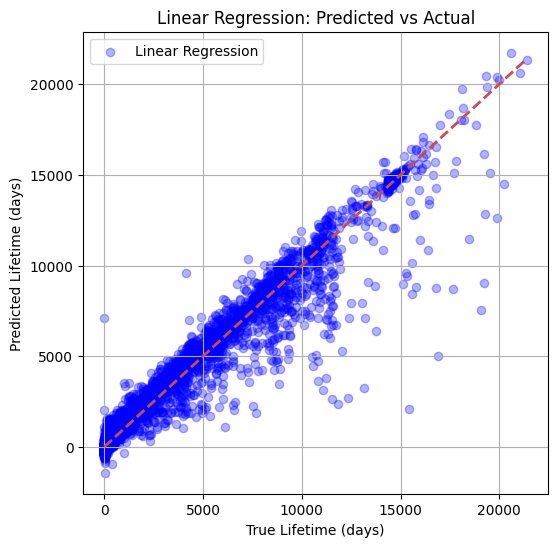

In [39]:
# visualize evaluation
plt.style.use('default')
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_lr1, alpha=0.3, label="Linear Regression", color="blue")
plt.xlabel("True Lifetime (days)")
plt.ylabel("Predicted Lifetime (days)")
plt.title("Linear Regression: Predicted vs Actual")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.legend()
plt.grid(True)
plt.show()

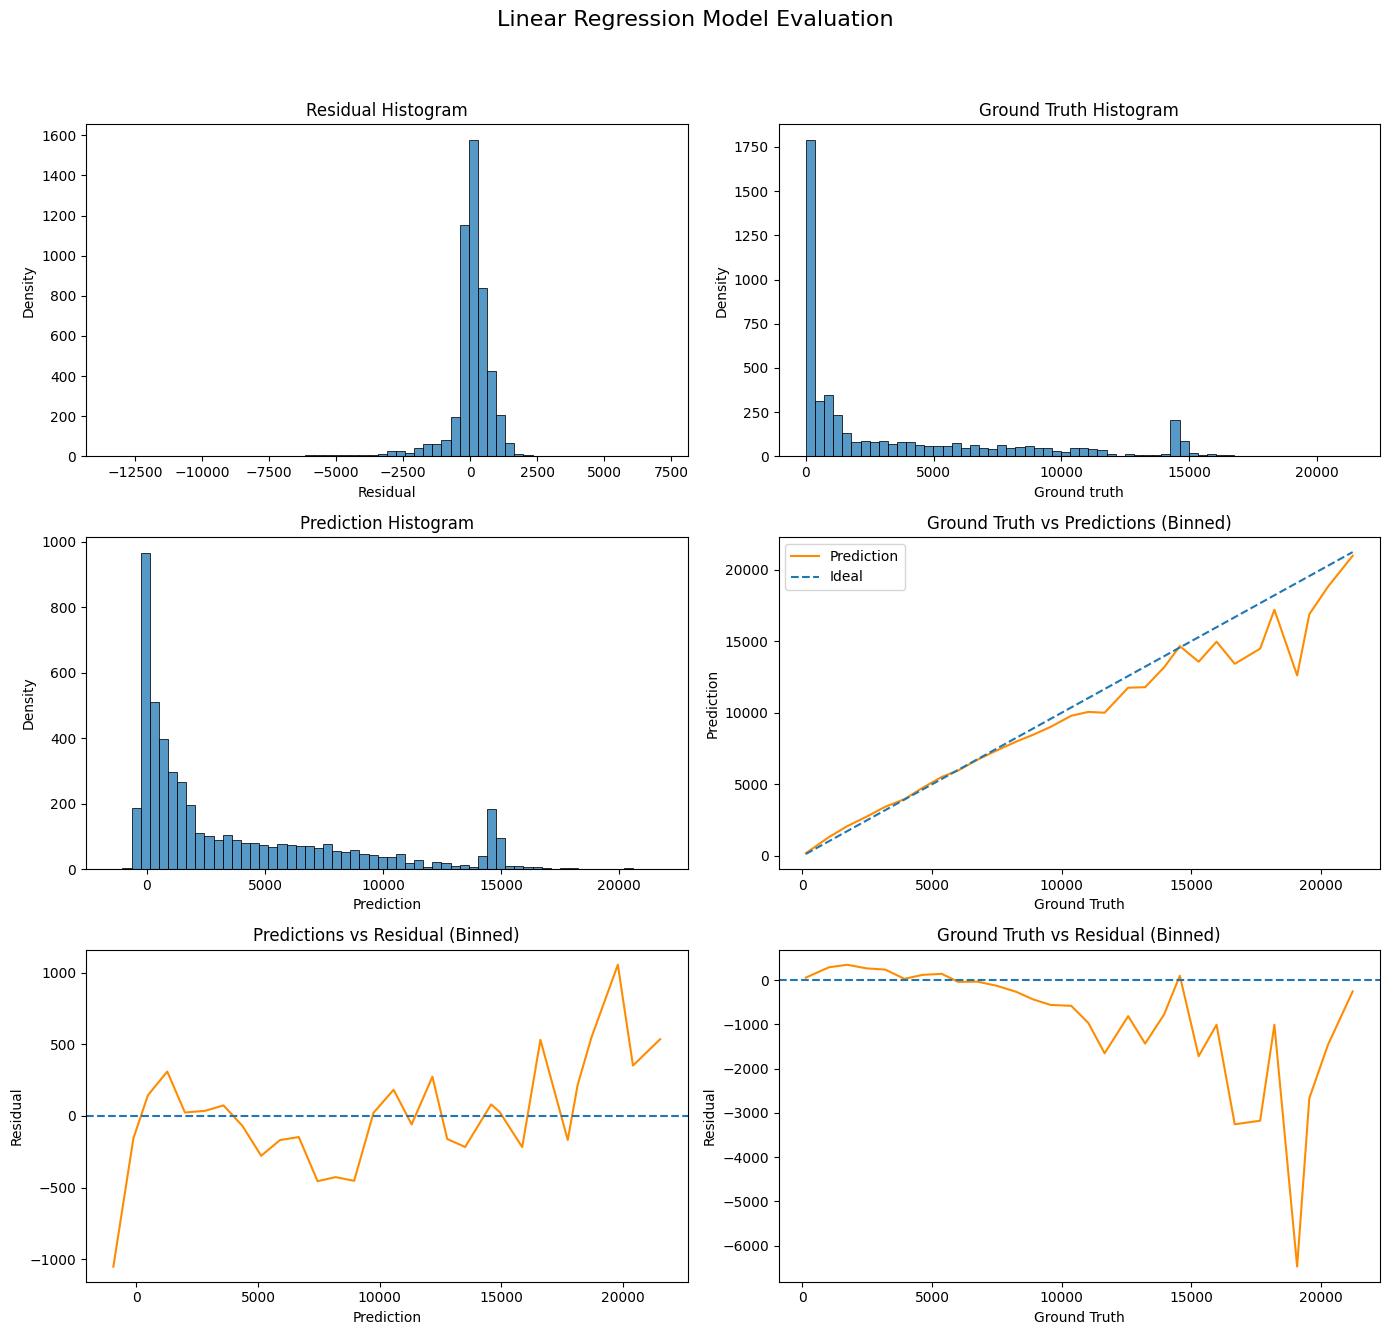

In [40]:
plot_model_evaluation(y_test, y_pred_lr1, title="Linear Regression Model Evaluation")

### 2. Log-Transformed Label 
#### Target variable is skewed with long right tail. Log transforming compresses large values and expands small ones, turning skewed data into something more normal-like, maybe improving predictions.

In [41]:
# log transform label
y_train_log = np.log1p(y_train)  # log(1 + x), safe for zero
y_test_log = np.log1p(y_test)

In [42]:
# train model
lr_model2 = LinearRegression()
lr_model2.fit(X_train, y_train_log)

LinearRegression()

In [43]:
# predict and invert the log
y_pred_lr2_log = lr_model2.predict(X_test)
y_pred_lr2 = np.expm1(y_pred_lr2_log)  # exp(x) - 1, inverse of log1p


In [44]:
# evaluate 
mae_lr2 = mean_absolute_error(y_test, y_pred_lr2)
mse_lr2 = mean_squared_error(y_test, y_pred_lr2)
rmse_lr2 = np.sqrt(mse_lr2)
r2_lr2 = r2_score(y_test, y_pred_lr2)

print("Log-Transformed Linear Regression Results:")
print(f"MAE: {mae_lr2:.2f}")
print(f"MSE: {mse_lr2:.2f}")
print(f"RMSE: {rmse_lr2:.2f}")
print(f"R² Score: {r2_lr2:.2f}")

Log-Transformed Linear Regression Results:
MAE: 7738.86
MSE: 31054829190.23
RMSE: 176223.80
R² Score: -1407.34


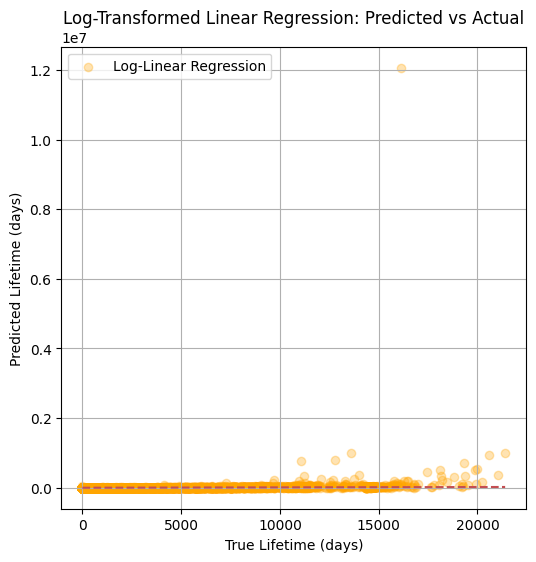

In [45]:
# visualize
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_lr2, alpha=0.3, color="orange", label="Log-Linear Regression")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("True Lifetime (days)")
plt.ylabel("Predicted Lifetime (days)")
plt.title("Log-Transformed Linear Regression: Predicted vs Actual")
plt.legend()
plt.grid(True)
plt.show()


#### Model performed really bad. Log-transforming compresses big values, making them harder for a linear model to differentiate. But the inverse exp() amplifies any small mistake into huge errors. Linear regression simply didn’t learn a good enough representation in log space.

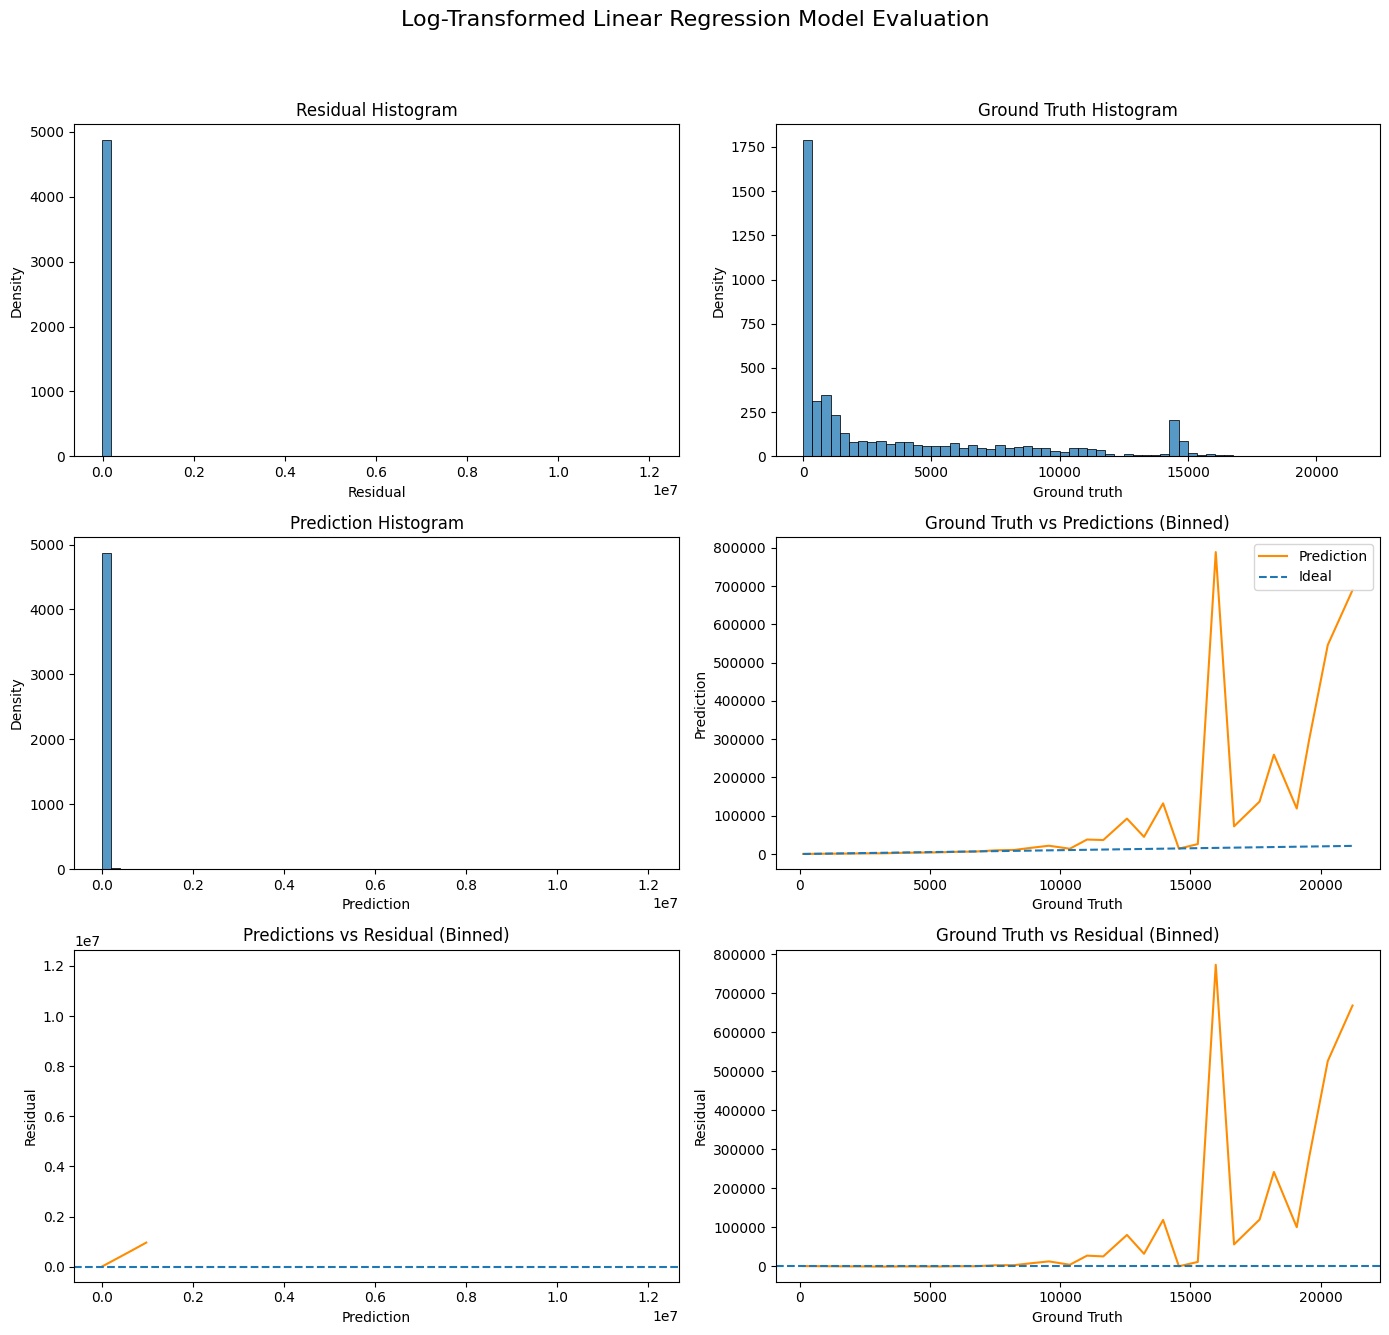

In [46]:
plot_model_evaluation(y_test, y_pred_lr2, title="Log-Transformed Linear Regression Model Evaluation")